# Sigue el diseño y las particiones de validación sin fuga

**Pregunta:** ¿Cómo cambia el orden de los modelos entre interpolación por filas y validación que excluye un caso?

Nivel: 2. Requisitos previos: Nivel 1: Construye un ejemplo de aprendizaje para procesamiento de minerales. Tiempo de lectura: 32 minutos.

## Objetivos

Genera un diseño determinista pequeño con el pipeline OreFlow, inspecciona particiones de interpolación y caso completo no visto, y relaciónalas con la validación comprometida de tamaño completo.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 2 sobre 03-learning, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/contract/operating_contract.json` y `data/derived/learning.json`, licencia MIT del proyecto. Las filas son simulaciones de escenarios propios, no mediciones de planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El constructor muestrea entradas factibles dentro del Contrato 1, ejecuta el motor y crea objetivos y características físicas. Interpolación retiene filas con semilla dentro de cada caso. Leave-one-case-out retiene un caso completo; la transferencia por grupo retiene también casos hermanos. No son protocolos intercambiables: el segundo mide transferencia a un caso nunca visto.

Construye un diseño pequeño con semilla para dos casos. OreFlow genera cada fila con su constructor y solver de producción; no se ingresan datos manualmente.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.learning import build_design, interpolation_split, leave_one_case_out

# Paso ejecutable del método OreFlow explicado en la celda anterior.
contract = json.loads(
    (repo / "data/derived/contract/operating_contract.json").read_text(encoding="utf-8")
)
selected = tuple(
    item for item in CASES if item.id in ("copper_porphyry_soft", "iron_magnetite_fine")
)
# Paso ejecutable del método OreFlow explicado en la celda anterior.
import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()):
    design = build_design(contract, cases=selected, per_case=8, seed=20261026)
x, y, case_of = design["x"], design["y"], design["case"]
print("matriz de diseño:", x.shape, "| target matrix:", y.shape)
print(
    "filas por caso:", {str(name): int((case_of == name).sum()) for name in dict.fromkeys(case_of)}
)


matriz de diseño: (16, 22) | target matrix: (16, 3)
filas por caso: {'copper_porphyry_soft': 8, 'iron_magnetite_fine': 8}


Crea ambos protocolos de validación y verifica sus límites contra fuga. Los casos de prueba de un fold de caso completo no pueden aparecer en los índices de entrenamiento.

In [3]:
# Crea ambos protocolos de validación y verifica sus límites contra fuga.
train_idx, test_idx = interpolation_split(case_of, 0.25, seed=20261026)
folds = leave_one_case_out(case_of)
print("interpolation train/test:", len(train_idx), len(test_idx))
print("whole-folds por caso:", [(name, len(train), len(test)) for name, train, test in folds])
assert set(case_of[train_idx]) == set(case_of[test_idx])
assert all(set(case_of[train]).isdisjoint(set(case_of[test])) for _, train, test in folds)


interpolation train/test: 12 4
whole-folds por caso: [('copper_porphyry_soft', 8, 8), ('iron_magnetite_fine', 8, 8)]


Lee la evaluación de producción por separado de esta muestra didáctica. El registro comprometido se horneó con los doce casos y la configuración completa declarada.

In [4]:
# Lee la evaluación de producción por separado de esta muestra didáctica.
record = json.loads((repo / "data/derived/learning.json").read_text(encoding="utf-8"))
print("versión del motor:", record["engine_version"])
print("production design rows:", record["design"]["rows"])
print(
    "interpolation train/test:",
    record["interpolation"]["train_rows"],
    record["interpolation"]["test_rows"],
)
print("case holdouts:", len(record["leave_one_case_out"]))
print("ore-group holdouts:", len(record["leave_one_group_out"]))


versión del motor: 0.10.006
production design rows: 3072
interpolation train/test: 2460 612
case holdouts: 12
ore-group holdouts: 2


En el caso de nivel 2 sobre 03 learning, la corrida con 0.8× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 03 learning, con 0.8× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [5]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


En el caso de nivel 2 sobre 03 learning, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 03 learning, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


En el caso de nivel 2 sobre 03 learning, la corrida con 1.0× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 03 learning, con 1.0× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


En el caso de nivel 2 sobre 03 learning, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 03 learning, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


En el caso de nivel 2 sobre 03 learning, la corrida con 1.2× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 2 sobre 03 learning, con 1.2× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


En la lección de nivel 2 sobre 03 learning, la lectura del gráfico 1 considera en esta figura del nivel 2 sobre 03 learning, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 2 sobre 03 learning, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 2 sobre 03 learning, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 2 sobre 03 learning, la lectura del gráfico 4 considera en «Sigue el diseño y las particiones de validación sin fuga», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

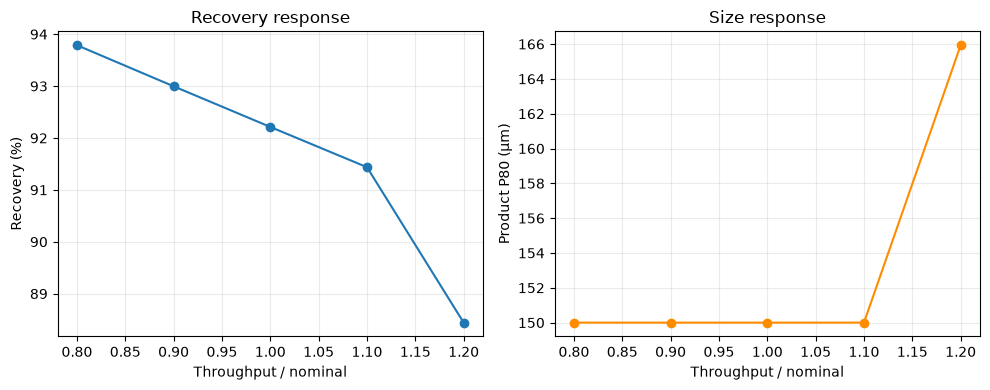

In [10]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 25 de nivel 2 sobre 03 learning informa salidas de puntos operativos resueltos por separado. En la figura 25 de nivel 2 sobre 03 learning, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 25 de nivel 2 sobre 03 learning, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 25 solo guía la comparación.

Compara los errores entre casos completos excluidos del entrenamiento. La dispersión muestra qué estimadores son más estables cuando falta un mineral; estos pliegues simulados tampoco miden transferencia a una planta en operación.

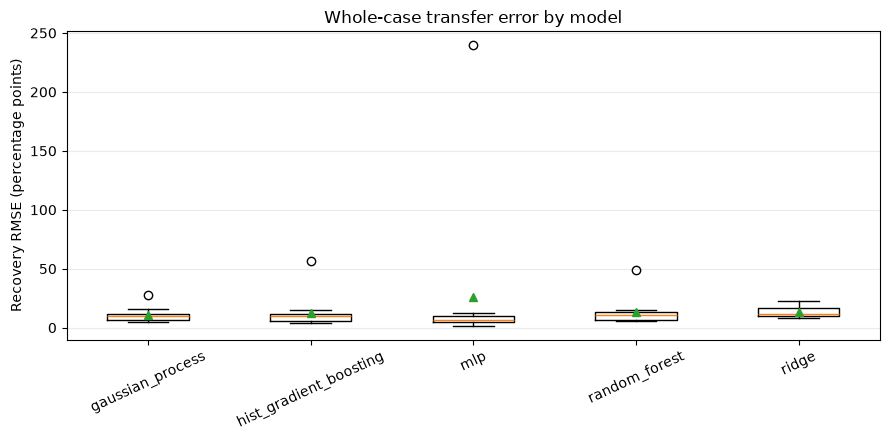

In [11]:
# Display the distribution of measured per-case errors for each fitted model.
case_models = record["leave_one_case_out"]
model_names = sorted(case_models[0]["models"])
fold_errors = [
    [fold["models"][name]["recovery_pct"]["rmse"] for fold in case_models] for name in model_names
]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(fold_errors, tick_labels=model_names, showmeans=True)
ax.set(ylabel="Recovery RMSE (percentage points)", title="Whole-case transfer error by model")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


En el nivel 2 de 03 learning, la interpretación 1 es que todos los objetivos supervisados de este repositorio los genera el motor de proceso OreFlow. En el nivel 2 de 03 learning, la interpretación 2 es que por ello, el aprendiz aproxima un simulador determinista, no una planta instrumentada. En el nivel 2 de 03 learning, la interpretación 3 es que las particiones de interpolación miden desempeño entre estados de casos presentes en entrenamiento. En el nivel 2 de 03 learning, la interpretación 4 es que las particiones que excluyen un caso o un grupo mineral retiran ejemplos cada vez más relacionados y plantean preguntas de transferencia más exigentes. En el nivel 2 de 03 learning, la interpretación 5 es que la unidad de partición debe coincidir con el uso previsto: una partición aleatoria por fila puede filtrar la identidad del caso mediante variables de proceso correlacionadas. En el nivel 2 de 03 learning, la interpretación 6 es que el escalamiento, la selección de variables y el ajuste de hiperparámetros deben ocurrir dentro de cada pliegue. En el nivel 2 de 03 learning, la interpretación 7 es que informa errores por objetivo y grupo reservado, no solo una puntuación agregada, porque un promedio bueno puede ocultar fallas severas para una familia mineral desconocida. En el nivel 2 de 03 learning, la interpretación 8 es que los intervalos predictivos requieren cobertura empírica. En el nivel 2 de 03 learning, la interpretación 9 es que estas evaluaciones no establecen causalidad ni validan una decisión operativa. En el nivel 2 de 03 learning, la interpretación 10 es que para esas preguntas separadas hacen falta observaciones de planta y una función de pérdida específica de la decisión. En el nivel 2 de 03 learning, la interpretación 11 es que el diseño versionado reúne 3.072 estados simulados de doce circuitos de autoría propia. En el nivel 2 de 03 learning, la interpretación 12 es que ese tamaño mejora la repetibilidad del experimento, pero no genera 3.072 escenarios geológicos independientes: las filas comparten definiciones de caso, parámetros minerales y supuestos de circuito. En el nivel 2 de 03 learning, la interpretación 13 es que un modelo entrenado con esas etiquetas puede reproducir muy bien el simulador y aun así equivocarse sobre una planta real. En el nivel 2 de 03 learning, la interpretación 14 es que para evaluar transferencia, inspecciona residuos por caso, escala de los objetivos y grupos minerales ausentes del entrenamiento. En el nivel 2 de 03 learning, la interpretación 15 es que una partición agrupada evita que filas casi duplicadas crucen la separación, pero no prueba una familia mineral que el estudio nunca incluyó. En el nivel 2 de 03 learning, la interpretación 16 es que compara cada predicción aprendida con el resultado exacto de proceso antes de usarla para ordenar decisiones operativas. En el nivel 2 de 03 learning, la extensión 1 muestra que una comparación justa usa los mismos pliegues, objetivos, preprocesamiento y presupuesto de ajuste. En el nivel 2 de 03 learning, la extensión 2 muestra que el estimador seleccionado debe elegirse dentro de los pliegues de entrenamiento porque usar casos reservados para elegirlo convierte la puntuación final en otro resultado de ajuste. En el nivel 2 de 03 learning, la extensión 3 muestra que conserva una referencia simple, como el predictor de media de entrenamiento, y muestra la distribución entre grupos reservados para evaluar si la complejidad adicional ayuda a transferir y no solo a interpolar.

## Resultados

**Respuesta:** En esta lección de nivel 2 sobre 03 learning, el circuito ejecutado informa una recuperación de 93.788 por ciento para «Sigue el diseño y las particiones de validación sin fuga» en el primer tratamiento controlado.

El diseño pequeño hace inspeccionables las particiones; el registro completo aporta métricas de ajuste. Interpolación estima comportamiento dentro de casos representados; retener casos o grupos prueba transferencia. Ninguno es validación de planta si las etiquetas proceden del motor.

## Resumen

Ejecutaste las funciones reales de diseño y partición y verificaste los límites de fuga. Mantén separada la muestra ilustrativa de la evaluación de bake completo.

## Referencias

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.1023/A:1010933404324